# 3D Gaussian Splatting — MVP in pure PyTorch

This notebook is a *minimal*, end-to-end implementation of 3D Gaussian Splatting
([Kerbl et al., SIGGRAPH 2023](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/))
that fits in a single file with no custom CUDA kernels.

The full 3DGS system has three main pieces:

1. **A scene representation** — a set of 3D Gaussians, each with a mean, covariance,
   color (a spherical-harmonics function of view direction), and opacity.
2. **A differentiable rasterizer** — projects each 3D Gaussian to a 2D Gaussian on
   the image plane, sorts them by depth, and alpha-composites them per-pixel.
3. **An adaptive optimizer** — densifies (clones / splits) Gaussians where gradients
   are large and prunes ones with low opacity.

For the MVP we keep (1) and (2) and drop (3). We also use a flat per-Gaussian RGB
color instead of spherical harmonics, and skip the tile-based rasterizer in favor
of a brute-force per-pixel evaluation. The math (projection, 2D covariance via the
projection Jacobian, front-to-back alpha compositing) is exactly the same as the
paper.

By the end we will:

- render a small synthetic scene of colored 3D Gaussians from several known cameras,
- start from a fresh random set of Gaussians,
- and fit it to those rendered images by gradient descent — including a held-out
  *novel view* that we never train on.

In [1]:
import math
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("device =", device)

device = cpu


## 1. Camera model

We use a standard pinhole camera with the OpenCV / COLMAP convention: the camera
local axes are `x` right, `y` down, `z` forward, so a point in front of the camera
has `z_cam > 0`. Intrinsics `(fx, fy, cx, cy)` define the projection

$$
u = f_x \, \frac{x_c}{z_c} + c_x, \qquad
v = f_y \, \frac{y_c}{z_c} + c_y.
$$

The extrinsics are stored as a single 4×4 world→camera matrix `view`.
`look_at` builds one given a camera position, a look-at target, and an up vector.

In [2]:
def look_at(eye, target, up=(0.0, 1.0, 0.0)) -> torch.Tensor:
    # World -> camera 4x4. Camera local axes: x=right, y=down, z=forward.
    eye = torch.as_tensor(eye, dtype=torch.float32)
    target = torch.as_tensor(target, dtype=torch.float32)
    up = torch.as_tensor(up, dtype=torch.float32)

    f = target - eye
    f = f / f.norm()
    r = torch.linalg.cross(f, -up); r = r / r.norm()
    d = torch.linalg.cross(f, r)  # camera "down"

    R = torch.stack([r, d, f], dim=0)   # 3x3 world->camera
    t = -R @ eye
    Rt = torch.eye(4)
    Rt[:3, :3] = R
    Rt[:3, 3] = t
    return Rt


@dataclass
class PinholeCamera:
    fx: float
    fy: float
    cx: float
    cy: float
    width: int
    height: int
    view: torch.Tensor  # 4x4 world->camera

    def to(self, device):
        return PinholeCamera(self.fx, self.fy, self.cx, self.cy,
                             self.width, self.height, self.view.to(device))


def make_camera(eye, target, width=64, height=64, fov_deg=50.0):
    fov = math.radians(fov_deg)
    fx = fy = 0.5 * width / math.tan(0.5 * fov)
    cx = (width - 1) * 0.5
    cy = (height - 1) * 0.5
    return PinholeCamera(fx, fy, cx, cy, width, height, look_at(eye, target))

## 2. Gaussian parameterization

Each Gaussian is described by:

- **Mean** $\mu \in \mathbb{R}^3$.
- **Covariance** $\Sigma \in \mathbb{R}^{3\times 3}$, which we parameterize as
  $\Sigma = R\,S\,S^\top R^\top$ where $R$ is a rotation (from a unit quaternion)
  and $S = \mathrm{diag}(s_x, s_y, s_z)$ a positive diagonal scale matrix. This
  factorization keeps $\Sigma$ symmetric positive semidefinite for free.
- **Color** $c \in [0, 1]^3$ (we use a flat RGB; full 3DGS uses spherical harmonics
  to make color view-dependent).
- **Opacity** $\alpha \in [0, 1]$.

In [3]:
def quat_to_rotmat(q: torch.Tensor) -> torch.Tensor:
    # Quaternion (w, x, y, z) -> 3x3 rotation matrix. Auto-normalizes.
    q = q / q.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    w, x, y, z = q.unbind(-1)
    R = torch.stack([
        1 - 2 * (y * y + z * z), 2 * (x * y - z * w),     2 * (x * z + y * w),
        2 * (x * y + z * w),     1 - 2 * (x * x + z * z), 2 * (y * z - x * w),
        2 * (x * z - y * w),     2 * (y * z + x * w),     1 - 2 * (x * x + y * y),
    ], dim=-1).reshape(*q.shape[:-1], 3, 3)
    return R


def build_covariance_3d(scales: torch.Tensor, quats: torch.Tensor) -> torch.Tensor:
    # Sigma = R S S^T R^T, shape (N, 3, 3).
    R = quat_to_rotmat(quats)
    S = torch.diag_embed(scales)
    M = R @ S
    return M @ M.transpose(-1, -2)

## 3. Forward rasterizer

For each frame we need to splat every Gaussian onto the image plane and blend
them. Three pieces:

**3.1 Project the mean.** We transform $\mu$ into camera coordinates with the
view matrix and apply the pinhole equations above to get the 2D pixel center
$\mu_{2d}$.

**3.2 Project the covariance.** A 3D Gaussian projected through a non-linear
perspective transform is *not* exactly a 2D Gaussian. The standard 3DGS
approximation is to linearize the projection at $\mu$ and propagate the
covariance through that linearization (this is the EWA / Zwicker et al. 2001
trick):

$$
\Sigma_{2d} \;=\; J\, W \,\Sigma\, W^{\!\top}\!J^{\!\top},
$$

where $W$ is the world→camera rotation and $J$ is the 2×3 Jacobian of the
projection $(x_c, y_c, z_c) \mapsto (u, v)$ at the Gaussian's center:

$$
J = \begin{bmatrix}
f_x / z_c & 0         & -f_x x_c / z_c^2 \\
0         & f_y / z_c & -f_y y_c / z_c^2
\end{bmatrix}.
$$

We add a small isotropic blur to $\Sigma_{2d}$ ("dilation filter" in the paper)
to keep things well-conditioned and ensure each splat covers at least ~1 pixel.

**3.3 Composite front-to-back.** Sort the Gaussians by camera-space depth, and
for each pixel $p$ accumulate

$$
g_i(p) = \exp\!\big(-\tfrac12 (p - \mu_{2d,i})^\top \Sigma_{2d,i}^{-1} (p - \mu_{2d,i})\big),
\quad
\alpha'_i = \alpha_i\, g_i(p),
$$

$$
C(p) = \sum_i c_i\, \alpha'_i \prod_{j<i}(1 - \alpha'_j).
$$

This is the same volume-rendering equation NeRF uses, just with anisotropic 2D
Gaussian weights instead of dense ray samples.

In [4]:
def render(
    camera: PinholeCamera,
    means: torch.Tensor,        # (N, 3)
    scales: torch.Tensor,       # (N, 3)  positive
    quats: torch.Tensor,        # (N, 4)
    colors: torch.Tensor,       # (N, 3)  in [0, 1]
    opacities: torch.Tensor,    # (N,)    in [0, 1]
    bg: torch.Tensor | None = None,
    blur: float = 0.1,
    near: float = 0.1,
):
    device = means.device
    H, W = camera.height, camera.width
    R_w2c = camera.view[:3, :3].to(device)
    t_w2c = camera.view[:3, 3].to(device)

    # World -> camera
    means_c = means @ R_w2c.T + t_w2c
    z = means_c[:, 2]
    valid = z > near
    z_safe = z.clamp_min(near)

    # Project means
    x_pix = means_c[:, 0] * camera.fx / z_safe + camera.cx
    y_pix = means_c[:, 1] * camera.fy / z_safe + camera.cy
    means_2d = torch.stack([x_pix, y_pix], dim=-1)

    # 3D covariance in camera frame
    Sigma_w = build_covariance_3d(scales, quats)
    Sigma_c = R_w2c @ Sigma_w @ R_w2c.T

    # Projection Jacobian at each mean
    N = means.shape[0]
    J = torch.zeros(N, 2, 3, device=device)
    fx, fy = camera.fx, camera.fy
    xc, yc, zc = means_c[:, 0], means_c[:, 1], z_safe
    J[:, 0, 0] = fx / zc
    J[:, 0, 2] = -fx * xc / (zc * zc)
    J[:, 1, 1] = fy / zc
    J[:, 1, 2] = -fy * yc / (zc * zc)

    Sigma_2d = J @ Sigma_c @ J.transpose(-1, -2)
    Sigma_2d = Sigma_2d + torch.eye(2, device=device) * blur  # low-pass / dilation

    # Sort by depth (nearest first)
    order = torch.argsort(z, descending=False)
    means_2d = means_2d[order]
    Sigma_2d = Sigma_2d[order]
    colors_s = colors[order]
    opac_s = opacities[order]
    valid_s = valid[order]

    # Inverse 2D covariance, closed form
    a = Sigma_2d[:, 0, 0]; b = Sigma_2d[:, 0, 1]; d_ = Sigma_2d[:, 1, 1]
    det = (a * d_ - b * b).clamp_min(1e-8)
    inv00 = d_ / det
    inv11 = a  / det
    inv01 = -b / det

    # Pixel grid
    yy, xx = torch.meshgrid(
        torch.arange(H, device=device, dtype=torch.float32),
        torch.arange(W, device=device, dtype=torch.float32),
        indexing="ij",
    )

    img = torch.zeros(H, W, 3, device=device)
    T = torch.ones(H, W, device=device)

    for i in range(means_2d.shape[0]):
        if not valid_s[i]:
            continue
        dx = xx - means_2d[i, 0]
        dy = yy - means_2d[i, 1]
        m = inv00[i] * dx * dx + 2.0 * inv01[i] * dx * dy + inv11[i] * dy * dy
        g = torch.exp(-0.5 * m)
        alpha_i = (opac_s[i] * g).clamp(0.0, 0.999)
        contrib = T * alpha_i
        img = img + contrib.unsqueeze(-1) * colors_s[i]
        T = T * (1.0 - alpha_i)

    if bg is not None:
        img = img + T.unsqueeze(-1) * bg.to(device)
    return img, 1.0 - T

A quick note on the depth sort: `argsort` is not differentiable across
order-changes, so gradients can't push two Gaussians past each other in depth in
a single step. In practice this is fine — gradients still flow through the
**values** ($\mu$, $\Sigma$, color, opacity) given the ordering, and the order
re-evaluates at the next forward pass.

## 4. Trainable model

We expose the parameters through "raw" tensors with appropriate activations so
that the optimizer can move freely while the constraints (positive scales,
unit-norm quaternions, $[0, 1]$ colors and opacities) are kept implicitly.

In [5]:
class GaussianModel(torch.nn.Module):
    def __init__(self, n: int, scene_radius: float = 1.0, init_scale: float = 0.15, seed: int = 0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.means = torch.nn.Parameter(
            (torch.rand(n, 3, generator=g) * 2.0 - 1.0) * scene_radius
        )
        self.log_scales = torch.nn.Parameter(torch.full((n, 3), math.log(init_scale)))
        self.quats = torch.nn.Parameter(
            torch.tensor([1.0, 0.0, 0.0, 0.0]).repeat(n, 1)
            + 0.01 * torch.randn(n, 4, generator=g)
        )
        self.colors_logits = torch.nn.Parameter(torch.randn(n, 3, generator=g) * 0.5)
        self.opacities_logits = torch.nn.Parameter(torch.zeros(n))

    @property
    def scales(self): return torch.exp(self.log_scales)
    @property
    def colors(self): return torch.sigmoid(self.colors_logits)
    @property
    def opacities(self): return torch.sigmoid(self.opacities_logits)

    def render(self, camera, **kwargs):
        return render(camera, self.means, self.scales, self.quats,
                      self.colors, self.opacities, **kwargs)

## 5. A tiny synthetic "ground truth" scene

We hand-place five colored, mostly-isotropic 3D Gaussians sitting in front of
the world origin. We then render them from four training cameras and one
held-out *novel* camera. The training images are the only thing the optimizer
will see.

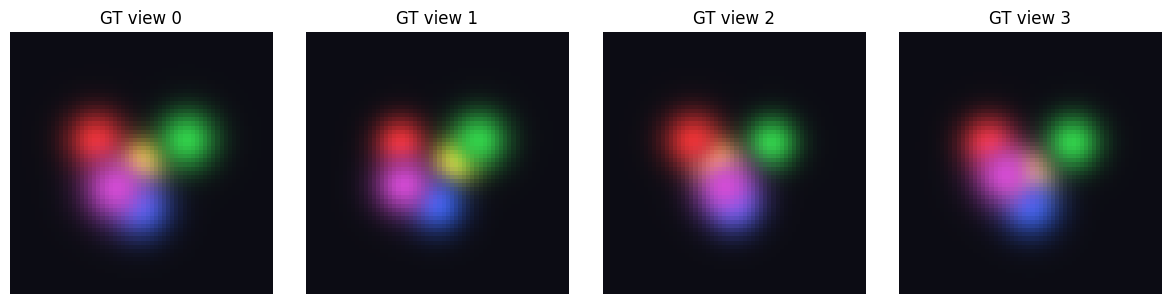

In [6]:
def make_ground_truth():
    means = torch.tensor([
        [-0.4, -0.2, 2.5],
        [ 0.4, -0.2, 2.5],
        [ 0.0,  0.4, 2.5],
        [ 0.0,  0.0, 3.0],
        [-0.2,  0.2, 2.2],
    ])
    scales = torch.full((5, 3), 0.18)
    quats = torch.tensor([1.0, 0, 0, 0]).repeat(5, 1)
    colors = torch.tensor([
        [0.95, 0.20, 0.20],
        [0.20, 0.85, 0.30],
        [0.20, 0.40, 0.95],
        [0.95, 0.85, 0.20],
        [0.85, 0.30, 0.85],
    ])
    opacities = torch.full((5,), 0.95)
    return means, scales, quats, colors, opacities


H = W = 64
train_cams = [
    make_camera(eye=( 0.0, 0.0, 0.0), target=(0.0, 0.0, 1.0), width=W, height=H),
    make_camera(eye=( 1.0, 0.0, 0.0), target=(0.0, 0.0, 2.5), width=W, height=H),
    make_camera(eye=(-1.0, 0.0, 0.0), target=(0.0, 0.0, 2.5), width=W, height=H),
    make_camera(eye=( 0.0, 0.8, 0.0), target=(0.0, 0.0, 2.5), width=W, height=H),
]
novel_cam = make_camera(eye=(0.6, 0.4, 0.2), target=(0.0, 0.0, 2.5), width=W, height=H)

means_gt, scales_gt, quats_gt, colors_gt, opacities_gt = make_ground_truth()
means_gt = means_gt.to(device); scales_gt = scales_gt.to(device)
quats_gt = quats_gt.to(device); colors_gt = colors_gt.to(device)
opacities_gt = opacities_gt.to(device)

bg = torch.tensor([0.05, 0.05, 0.08], device=device)

with torch.no_grad():
    targets = [
        render(c.to(device), means_gt, scales_gt, quats_gt, colors_gt, opacities_gt, bg=bg)[0].detach()
        for c in train_cams
    ]

fig, axes = plt.subplots(1, len(train_cams), figsize=(3 * len(train_cams), 3))
for i, t in enumerate(targets):
    axes[i].imshow(t.cpu().numpy().clip(0, 1))
    axes[i].set_title(f"GT view {i}")
    axes[i].axis("off")
plt.tight_layout(); plt.show()

## 6. Fit a fresh set of Gaussians

We initialize 40 Gaussians with random means in front of the camera, and
optimize means / scales / rotations / colors / opacities to minimize a simple
L1 + MSE photometric loss on the four training views. We never use the novel
view for training.

iter    0  loss 0.1261


iter   50  loss 0.0080


iter  100  loss 0.0024


iter  150  loss 0.0012


iter  200  loss 0.0009


...

iter  400  loss 0.0007


iter  450  loss 0.0005


iter  500  loss 0.0005


iter  550  loss 0.0006


iter  599  loss 0.0006


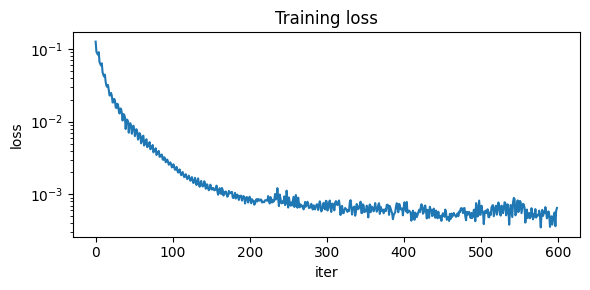

In [7]:
model = GaussianModel(n=40, scene_radius=0.6, init_scale=0.15, seed=42).to(device)
with torch.no_grad():
    # Push all Gaussians in front of the cameras.
    model.means.data[:, 2] = 2.0 + model.means.data[:, 2].abs()

opt = torch.optim.Adam([
    {"params": [model.means],            "lr": 5e-3},
    {"params": [model.log_scales],       "lr": 1e-2},
    {"params": [model.quats],            "lr": 5e-3},
    {"params": [model.colors_logits],    "lr": 5e-2},
    {"params": [model.opacities_logits], "lr": 5e-2},
])

losses = []
n_iters = 600
for it in range(n_iters):
    cam = train_cams[it % len(train_cams)].to(device)
    target = targets[it % len(train_cams)]
    img, _ = model.render(cam, bg=bg)
    loss = F.l1_loss(img, target) + 0.1 * F.mse_loss(img, target)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if it % 50 == 0 or it == n_iters - 1:
        print(f"iter {it:4d}  loss {loss.item():.4f}")

plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.xlabel("iter"); plt.ylabel("loss"); plt.yscale("log")
plt.title("Training loss"); plt.tight_layout(); plt.show()

## 7. Compare the fit, including a held-out novel view

The bottom row is the model rendered from the same training cameras and from
the novel camera the optimizer has *never seen*.

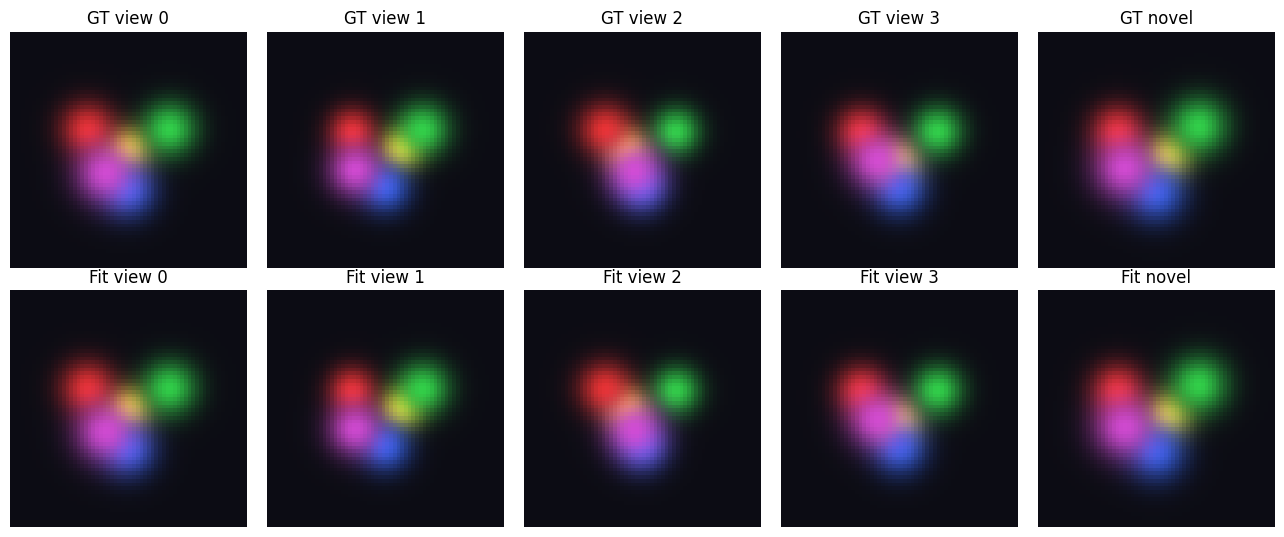

In [8]:
with torch.no_grad():
    novel_img, _ = model.render(novel_cam.to(device), bg=bg)
    gt_novel, _ = render(novel_cam.to(device), means_gt, scales_gt, quats_gt,
                         colors_gt, opacities_gt, bg=bg)
    fits = [model.render(c.to(device), bg=bg)[0] for c in train_cams]

ncols = len(train_cams) + 1
fig, axes = plt.subplots(2, ncols, figsize=(2.6 * ncols, 5.4))
for i, (t, p) in enumerate(zip(targets, fits)):
    axes[0, i].imshow(t.cpu().numpy().clip(0, 1)); axes[0, i].set_title(f"GT view {i}");  axes[0, i].axis("off")
    axes[1, i].imshow(p.cpu().numpy().clip(0, 1)); axes[1, i].set_title(f"Fit view {i}"); axes[1, i].axis("off")
axes[0, -1].imshow(gt_novel.cpu().numpy().clip(0, 1));   axes[0, -1].set_title("GT novel");  axes[0, -1].axis("off")
axes[1, -1].imshow(novel_img.cpu().numpy().clip(0, 1));  axes[1, -1].set_title("Fit novel"); axes[1, -1].axis("off")
plt.tight_layout(); plt.show()

## 8. What's missing vs. real 3D Gaussian Splatting

This MVP is deliberately tiny so the math is visible. To turn it into the real
thing you would add:

- **Tile-based CUDA rasterizer.** Our `for i in range(N)` loop is fine for tens
  of Gaussians but not for the millions in a real scan. The paper bins
  Gaussians into screen-space tiles and rasterizes each tile in parallel on the
  GPU.
- **Spherical-harmonics color.** Replace the flat per-Gaussian RGB with SH
  coefficients evaluated at the view direction so highlights move correctly
  with the camera.
- **Adaptive density control.** Periodically *clone* / *split* Gaussians whose
  positional gradients are large and *prune* ones with low opacity. This is
  what lets 3DGS go from a sparse SfM point cloud to millions of well-placed
  Gaussians.
- **Real captures.** Initialize from COLMAP SfM points and use real images
  from many cameras instead of one synthetic scene.
- **More careful losses.** SSIM term, anisotropy regularizer on scales, etc.

Even with all of those stripped away, the basic loop — *project, splat,
composite, take a gradient step* — is exactly what runs in the production
system.